# Sprawozdanie — Zajęcia 1

**Zbiór danych: FashionMNIST.**

**Uzasadnienie wyboru:** FashionMNIST (70 000 obrazów 28×28, skala szarości, 10 klas odzieży) jest istotnie trudniejszy od klasycznego MNIST, a jednocześnie wystarczająco mały, by MLP trenował się w kilkadziesiąt sekund na CPU. Obraz ma jeden kanał, więc `in_dim = 784`, a model z ćwiczenia można użyć bez zmian. CIFAR-10 (3×32×32, `in_dim = 3072`) dla MLP daje zwykle tylko ok. 50–55% accuracy, co mało mówi o wpływie architektury — MLP ignoruje strukturę przestrzenną, a to na CIFAR-10 jest głównym ograniczeniem.

In [5]:
import time, itertools
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torchvision
from torchvision import transforms
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

SEED = 0
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__, "| urządzenie:", device)

def set_seed(s=SEED):
    torch.manual_seed(s); np.random.seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
set_seed()

PyTorch: 2.14.1+cpu | urządzenie: cpu


## 1. Dane

In [6]:
mean, std = 0.2860, 0.3530
tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize((mean,), (std,))])
train_ds = torchvision.datasets.FashionMNIST("./data", train=True,  download=True, transform=tf)
test_ds  = torchvision.datasets.FashionMNIST("./data", train=False, download=True, transform=tf)
classes = train_ds.classes
print("Klasy:", classes)
print("Trening:", len(train_ds), "| Test:", len(test_ds))

def make_loaders(bs=128):
    g = torch.Generator().manual_seed(SEED)
    return (DataLoader(train_ds, batch_size=bs, shuffle=True, generator=g),
            DataLoader(test_ds, batch_size=256, shuffle=False))
train_dl, test_dl = make_loaders()

100.0%
100.0%
100.0%
100.0%

Klasy: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
Trening: 60000 | Test: 10000


## 2. Model (uogólniony MLP) i funkcje pomocnicze

In [14]:
class MLP(nn.Module):
    def __init__(self, in_dim=28*28, hidden=(256, 128), n_classes=10):
        super().__init__()
        layers, prev = [nn.Flatten()], in_dim
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.ReLU()]
            prev = h
        layers.append(nn.Linear(prev, n_classes))
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x)

def count_params(m):
    return sum(p.numel() for p in m.parameters())

def evaluate(model, dl):
    model.eval()
    correct = total = 0; loss_sum = 0.0
    crit = nn.CrossEntropyLoss(reduction="sum")
    with torch.no_grad():
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss_sum += crit(out, yb).item()
            correct += (out.argmax(1) == yb).sum().item()
            total += yb.numel()
    return loss_sum/total, correct/total

def train(hidden, epochs=10, lr=1e-3, verbose=True):
    set_seed()
    tr_dl, te_dl = make_loaders()
    model = MLP(hidden=hidden).to(device)
    crit = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {"train_loss": [], "test_loss": [], "test_acc": []}
    t0 = time.time()
    for ep in range(1, epochs+1):
        model.train(); run = 0.0
        for xb, yb in tr_dl:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = crit(model(xb), yb)
            loss.backward(); opt.step()
            run += loss.item()*yb.numel()
        tl, ta = evaluate(model, te_dl)
        hist["train_loss"].append(run/len(train_ds))
        hist["test_loss"].append(tl); hist["test_acc"].append(ta)
        if verbose:
            print(f"  ep {ep:2d} | train {hist['train_loss'][-1]:.3f} | test {tl:.3f} | acc {ta*100:.2f}%")
    return model, hist, time.time()-t0

## 3. Model bazowy

In [8]:
base_model, base_hist, _ = train((256, 128), epochs=8)
base_params = count_params(base_model)
base_acc = base_hist["test_acc"][-1]
print(f"\nMODEL BAZOWY: parametry = {base_params:,} | accuracy (test) = {base_acc*100:.2f}%")

  ep  1 | train 0.487 | test 0.408 | acc 84.89%
  ep  2 | train 0.348 | test 0.381 | acc 86.26%
  ep  3 | train 0.313 | test 0.358 | acc 86.96%
  ep  4 | train 0.288 | test 0.337 | acc 87.80%
  ep  5 | train 0.266 | test 0.344 | acc 88.06%
  ep  6 | train 0.250 | test 0.339 | acc 88.08%
  ep  7 | train 0.236 | test 0.323 | acc 88.51%
  ep  8 | train 0.222 | test 0.325 | acc 88.73%

MODEL BAZOWY: parametry = 235,146 | accuracy (test) = 88.73%


## 4. Wpływ architektury
Wszystkie warianty trenowane identycznie (10 epok, Adam, lr = 1e-3, ten sam seed). Jedyną zmienną jest `hidden`.

In [9]:
ARCHS = [(128,), (256, 128), (512, 256, 128), (1024, 512, 256, 128)]
EPOCHS = 10
results = {}
for h in ARCHS:
    print("Architektura", h)
    m, hi, dt = train(h, epochs=EPOCHS)
    results[h] = dict(model=m, hist=hi, params=count_params(m),
                      acc=hi["test_acc"][-1], best_acc=max(hi["test_acc"]),
                      gap=hi["test_loss"][-1]-hi["train_loss"][-1], time=dt)

print("\n| Architektura | Parametry | Accuracy (test, ost. epoka) | Najlepsza acc | Luka strat (test−trening) | Czas [s] |")
print("|---|---:|---:|---:|---:|---:|")
for h, r in results.items():
    print(f"| {h} | {r['params']:,} | {r['acc']*100:.2f}% | {r['best_acc']*100:.2f}% | {r['gap']:.3f} | {r['time']:.0f} |")

best_arch = max(results, key=lambda k: results[k]["acc"])
print("\nNajlepszy wariant:", best_arch)

Architektura (128,)
  ep  1 | train 0.491 | test 0.419 | acc 84.72%
  ep  2 | train 0.366 | test 0.386 | acc 85.89%
  ep  3 | train 0.329 | test 0.365 | acc 86.77%
  ep  4 | train 0.306 | test 0.341 | acc 87.69%
  ep  5 | train 0.285 | test 0.347 | acc 87.42%
  ep  6 | train 0.271 | test 0.349 | acc 87.49%
  ep  7 | train 0.256 | test 0.338 | acc 87.75%
  ep  8 | train 0.244 | test 0.334 | acc 88.25%
  ep  9 | train 0.232 | test 0.330 | acc 88.38%
  ep 10 | train 0.225 | test 0.343 | acc 87.97%
Architektura (256, 128)
  ep  1 | train 0.487 | test 0.408 | acc 84.89%
  ep  2 | train 0.348 | test 0.381 | acc 86.26%
  ep  3 | train 0.313 | test 0.358 | acc 86.96%
  ep  4 | train 0.288 | test 0.337 | acc 87.80%
  ep  5 | train 0.266 | test 0.344 | acc 88.06%
  ep  6 | train 0.250 | test 0.339 | acc 88.08%
  ep  7 | train 0.236 | test 0.323 | acc 88.51%
  ep  8 | train 0.222 | test 0.325 | acc 88.73%
  ep  9 | train 0.209 | test 0.335 | acc 88.71%
  ep 10 | train 0.198 | test 0.354 | acc 88.

| Architektura | Parametry | Accuracy (test) |
|---|---:|---:|
| (128,) | 101 770 | 87.97% |
| (256, 128) | 235 146 | 88.22% |
| (512, 256, 128) | 567 434 | 89.03% |
| (1024, 512, 256, 128) | 1 494 154 | 89.27% |

większa sieć = większe accuracy

## 5. Krzywe uczenia najlepszego wariantu

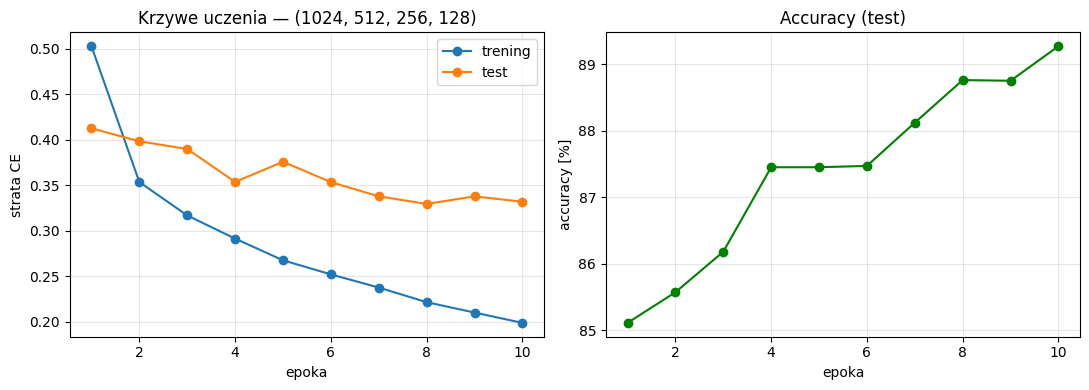

Minimum straty testowej w epoce 8; strata trening/test w ost. epoce: 0.199 / 0.332


In [10]:
bh = results[best_arch]["hist"]
ep = np.arange(1, EPOCHS+1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(ep, bh["train_loss"], "o-", label="trening")
ax1.plot(ep, bh["test_loss"], "o-", label="test")
ax1.set_xlabel("epoka"); ax1.set_ylabel("strata CE"); ax1.legend(); ax1.grid(alpha=.3)
ax1.set_title(f"Krzywe uczenia — {best_arch}")
ax2.plot(ep, [a*100 for a in bh["test_acc"]], "o-", color="green")
ax2.set_xlabel("epoka"); ax2.set_ylabel("accuracy [%]"); ax2.grid(alpha=.3)
ax2.set_title("Accuracy (test)")
plt.tight_layout(); plt.savefig("krzywe_uczenia.png", dpi=150); plt.show()

best_ep = int(np.argmin(bh["test_loss"]))+1
print(f"Minimum straty testowej w epoce {best_ep}; "
      f"strata trening/test w ost. epoce: {bh['train_loss'][-1]:.3f} / {bh['test_loss'][-1]:.3f}")

## 6. Siatka predykcji

Accuracy najlepszego modelu: 89.27%


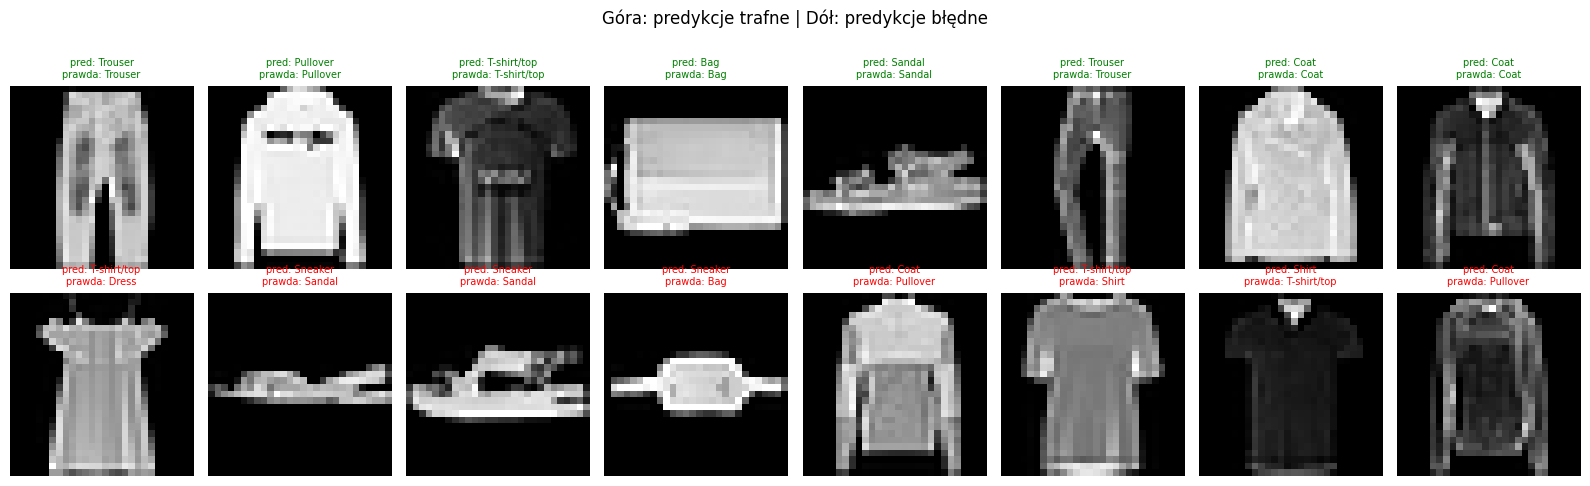

In [11]:
best_model = results[best_arch]["model"].eval()
preds, labels = [], []
with torch.no_grad():
    for xb, yb in test_dl:
        preds.append(best_model(xb.to(device)).argmax(1).cpu()); labels.append(yb)
preds = torch.cat(preds).numpy(); labels = torch.cat(labels).numpy()
final_acc = (preds == labels).mean()
print(f"Accuracy najlepszego modelu: {final_acc*100:.2f}%")

rng = np.random.default_rng(0)
ok_idx  = rng.choice(np.where(preds == labels)[0], 8, replace=False)
bad_idx = rng.choice(np.where(preds != labels)[0], 8, replace=False)
fig, axes = plt.subplots(2, 8, figsize=(16, 4.8))
for row, idxs, name in [(0, ok_idx, "trafne"), (1, bad_idx, "błędne")]:
    for ax, i in zip(axes[row], idxs):
        img = test_ds[i][0].squeeze()*std + mean
        ax.imshow(img, cmap="gray"); ax.axis("off")
        ax.set_title(f"pred: {classes[preds[i]]}\nprawda: {classes[labels[i]]}", fontsize=7,
                     color="green" if row == 0 else "red")
fig.suptitle("Góra: predykcje trafne | Dół: predykcje błędne", y=1.02)
plt.tight_layout(); plt.savefig("siatka_predykcji.png", dpi=150, bbox_inches="tight"); plt.show()

najtrudniejsza jest klasa Shirt

## 7. Macierz pomyłek i najtrudniejsza para klas

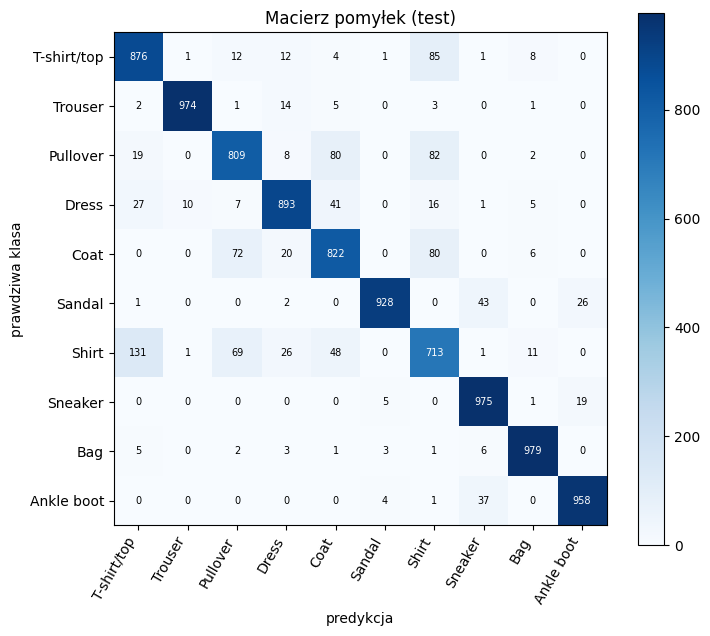

Najczęściej mylone pary klas:
  T-shirt/top <-> Shirt: 216 błędów (T-shirt/top->Shirt: 85, Shirt->T-shirt/top: 131)
  Pullover <-> Coat: 152 błędów (Pullover->Coat: 80, Coat->Pullover: 72)
  Pullover <-> Shirt: 151 błędów (Pullover->Shirt: 82, Shirt->Pullover: 69)
  Coat <-> Shirt: 128 błędów (Coat->Shirt: 80, Shirt->Coat: 48)
  Dress <-> Coat: 61 błędów (Dress->Coat: 41, Coat->Dress: 20)

Accuracy per klasa:
  Shirt         71.3%
  Pullover      80.9%
  Coat          82.2%
  T-shirt/top   87.6%
  Dress         89.3%
  Sandal        92.8%
  Ankle boot    95.8%
  Trouser       97.4%
  Sneaker       97.5%
  Bag           97.9%


In [ ]:
cm = confusion_matrix(labels, preds)
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set_xticklabels(classes, rotation=60, ha="right"); ax.set_yticklabels(classes)
for i, j in itertools.product(range(10), range(10)):
    ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
            color="white" if cm[i, j] > cm.max()/2 else "black")
ax.set_xlabel("predykcja"); ax.set_ylabel("prawdziwa klasa"); ax.set_title("Macierz pomyłek (test)")
plt.colorbar(im); plt.tight_layout(); plt.savefig("macierz_pomylek.png", dpi=150); plt.show()

pairs = []
for i in range(10):
    for j in range(i+1, 10):
        pairs.append((cm[i, j] + cm[j, i], classes[i], classes[j], cm[i, j], cm[j, i]))
pairs.sort(reverse=True)
print("Najczęściej mylone pary klas:")
for tot, a, b, ab, ba in pairs[:5]:
    print(f"  {a} <-> {b}: {tot} błędów ({a}->{b}: {ab}, {b}->{a}: {ba})")

per_class = cm.diagonal()/cm.sum(1)
print("\nAccuracy per klasa:")
for c, a in sorted(zip(classes, per_class), key=lambda t: t[1]):
    print(f"  {c:12s} {a*100:5.1f}%")

## 8. Wpływ liczby epok i współczynnika uczenia

lr = 0.0001
  acc po 5/10/20 ep: 87.11% / 88.19% / 89.33%
lr = 0.001
  acc po 5/10/20 ep: 87.45% / 89.27% / 89.87%
lr = 0.01
  acc po 5/10/20 ep: 85.28% / 84.81% / 85.90%


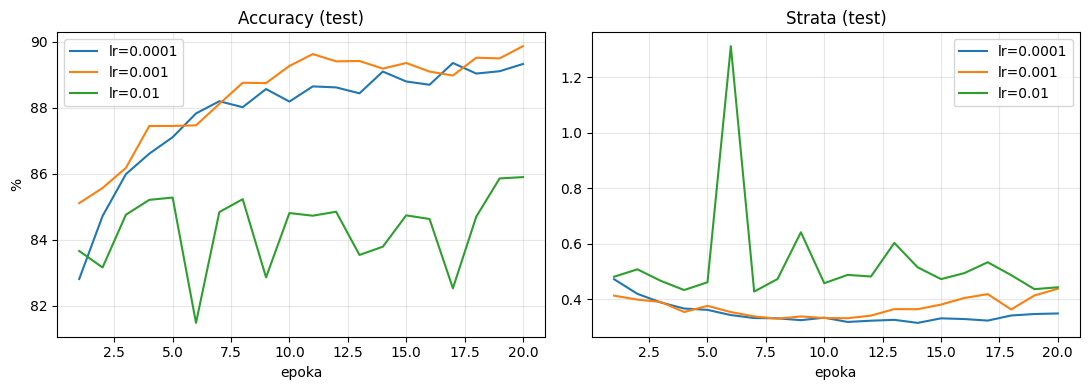

In [13]:
LRS = [1e-4, 1e-3, 1e-2]
EP_LONG = 20
lr_res = {}
for lr in LRS:
    print("lr =", lr)
    _, hi, _ = train(best_arch, epochs=EP_LONG, lr=lr, verbose=False)
    lr_res[lr] = hi
    print(f"  acc po 5/10/20 ep: {hi['test_acc'][4]*100:.2f}% / {hi['test_acc'][9]*100:.2f}% / {hi['test_acc'][19]*100:.2f}%")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
for lr, hi in lr_res.items():
    ax1.plot(range(1, EP_LONG+1), [a*100 for a in hi["test_acc"]], label=f"lr={lr}")
    ax2.plot(range(1, EP_LONG+1), hi["test_loss"], label=f"lr={lr}")
ax1.set_title("Accuracy (test)"); ax1.set_xlabel("epoka"); ax1.set_ylabel("%"); ax1.legend(); ax1.grid(alpha=.3)
ax2.set_title("Strata (test)"); ax2.set_xlabel("epoka"); ax2.legend(); ax2.grid(alpha=.3)
plt.tight_layout(); plt.savefig("wplyw_lr_epok.png", dpi=150); plt.show()

najlepszy wynik daje 1e-3 dłuższy trening troche pomaga ale wzrasta ryzyko przeuczenia